# 04 — Sales Analysis
## Superstore Sales Analytics

### Objetivo

Aprofundar a análise do desempenho comercial da Superstore, identificando como a receita evoluiu ao longo do período e quais fatores contribuíram para suas variações.

A análise será orientada principalmente pela relação entre receita, número de pedidos e valor médio por pedido, complementada pela avaliação da contribuição de categorias, segmentos e regiões.

O objetivo não é repetir os padrões já identificados na análise exploratória, mas investigar os principais drivers do desempenho de vendas e transformar as evidências encontradas em conclusões de negócio.

## 1. Configuração e Fonte Analítica

### 1.1 — Configuração do Ambiente e Caminhos

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "sales_data_clean.parquet"
)

print(f"Raiz do projeto: {PROJECT_ROOT}")
print(f"Fonte analítica: {PROCESSED_DATA_PATH}")
print(f"Arquivo disponível: {PROCESSED_DATA_PATH.exists()}")

Raiz do projeto: c:\superstore-analytics
Fonte analítica: c:\superstore-analytics\data\processed\sales_data_clean.parquet
Arquivo disponível: True


### 1.2 — Carregamento da Camada Processada

A análise utiliza diretamente a camada de dados processada e validada nas etapas anteriores do projeto.

O arquivo em formato Parquet preserva os tipos de dados definidos durante a preparação e representa a fonte analítica oficial para este notebook.

In [2]:
df = pd.read_parquet(PROCESSED_DATA_PATH)

print(f"Registros carregados: {len(df):,}")
print(f"Colunas disponíveis: {df.shape[1]}")

Registros carregados: 9,799
Colunas disponíveis: 19


### 1.3 — Validação da Base para Análise de Vendas

Antes das análises comerciais, são verificados apenas os requisitos essenciais para o cálculo consistente dos indicadores de vendas.

A validação confirma a disponibilidade das variáveis necessárias, a integridade das datas e a identificação dos pedidos. As verificações completas de qualidade permanecem documentadas nos notebooks anteriores.

In [3]:
required_columns = [
    "Order ID",
    "Order Date",
    "Sales",
    "Category",
    "Segment",
    "Region"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

validation_summary = {
    "Colunas obrigatórias ausentes": len(missing_columns),
    "Order ID ausentes": df["Order ID"].isna().sum(),
    "Order Date ausentes": df["Order Date"].isna().sum(),
    "Sales ausentes": df["Sales"].isna().sum(),
    "Pedidos distintos": df["Order ID"].nunique(),
    "Data inicial": df["Order Date"].min(),
    "Data final": df["Order Date"].max()
}

pd.Series(validation_summary, name="Resultado")

Colunas obrigatórias ausentes                      0
Order ID ausentes                                  0
Order Date ausentes                                0
Sales ausentes                                     0
Pedidos distintos                               4922
Data inicial                     2015-01-03 00:00:00
Data final                       2018-12-30 00:00:00
Name: Resultado, dtype: object

## 2. Visão Executiva de Vendas

Esta seção estabelece os principais indicadores comerciais e avalia sua evolução ao longo do período analisado.

### 2.1 — KPIs Comerciais

A visão executiva utiliza quatro indicadores centrais:

- **Receita Total** — valor total das vendas.
- **Número de Pedidos** — quantidade de pedidos distintos.
- **Ticket Médio** — receita média gerada por pedido.
- **Clientes Ativos** — quantidade de clientes distintos com compras no período.

Esses indicadores fornecem a base para distinguir crescimento decorrente de volume de pedidos daquele associado ao valor das transações.

In [4]:
orders = (
    df.groupby("Order ID", as_index=False)
      .agg(
          Order_Value=("Sales", "sum"),
          Customer_ID=("Customer ID", "first"),
          Order_Date=("Order Date", "first")
      )
)

print(f"Pedidos consolidados: {len(orders):,}")
print(f"Order IDs distintos: {orders[Order ID].nunique():,}")

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3931965357.py, line 11)

In [ ]:
total_revenue = df["Sales"].sum()
total_orders = orders["Order ID"].nunique()
active_customers = orders["Customer_ID"].nunique()
average_order_value = orders["Order_Value"].mean()

sales_kpis = pd.DataFrame({
    "Indicador": [
        "Receita Total",
        "Número de Pedidos",
        "Ticket Médio",
        "Clientes Ativos"
    ],
    "Valor": [
        total_revenue,
        total_orders,
        average_order_value,
        active_customers
    ]
})

sales_kpis_display = sales_kpis.copy()

sales_kpis_display["Valor"] = [
    f"${total_revenue:,.2f}",
    f"{total_orders:,}",
    f"${average_order_value:,.2f}",
    f"{active_customers:,}"
]

sales_kpis_display

,Indicador,Valor
0,Receita Total,"$2,261,255.41"
1,Número de Pedidos,"4,922"
2,Ticket Médio,$459.42
3,Clientes Ativos,793


### 2.2 — Evolução Anual dos Indicadores

A visão anual permite avaliar como receita, número de pedidos, ticket médio e base ativa de clientes evoluíram ao longo do período.

A comparação desses indicadores ajuda a distinguir crescimento associado ao aumento do volume de transações daquele relacionado à mudança no valor médio dos pedidos.

In [ ]:
annual_sales = (
    orders.assign(Year=orders["Order_Date"].dt.year)
          .groupby("Year", as_index=False)
          .agg(
              Revenue=("Order_Value", "sum"),
              Orders=("Order ID", "nunique"),
              Active_Customers=("Customer_ID", "nunique"),
              Average_Order_Value=("Order_Value", "mean")
          )
)

annual_sales

,Year,Revenue,Orders,Active_Customers,Average_Order_Value
0,2015,479574.8361,947,589,506.414822
1,2016,459436.0054,1019,567,450.869485
2,2017,600192.5500,1295,635,463.469151
3,2018,722052.0192,1661,690,434.709223


In [ ]:
revenue_difference = (
    annual_sales["Revenue"].sum() - total_revenue
)

print(f"Diferença de reconciliação: ${revenue_difference:,.2f}")

Diferença de reconciliação: $0.00


In [ ]:
annual_sales_display = annual_sales.copy()

annual_sales_display.style.format({
    "Year": "{:.0f}",
    "Revenue": "${:,.2f}",
    "Orders": "{:,.0f}",
    "Active_Customers": "{:,.0f}",
    "Average_Order_Value": "${:,.2f}"
})

,Year,Revenue,Orders,Active_Customers,Average_Order_Value
0,2015,"$479,574.84",947,589,$506.41
1,2016,"$459,436.01","1,019",567,$450.87
2,2017,"$600,192.55","1,295",635,$463.47
3,2018,"$722,052.02","1,661",690,$434.71


#### Interpretação

A evolução anual mostra mudanças relevantes na composição do desempenho comercial.

Entre 2015 e 2016, a receita diminui apesar do aumento no número de pedidos, acompanhada por redução do ticket médio.

A partir de 2017, a receita passa a crescer de forma expressiva, simultaneamente ao aumento do número de pedidos e da quantidade de clientes ativos.

Em 2018, a operação alcança a maior receita do período ($722.052,02) e o maior volume de pedidos (1.661), embora apresente o menor ticket médio ($434,71) entre os quatro anos.

Esse comportamento sugere que o crescimento recente da receita pode estar mais associado à expansão do volume de transações do que ao aumento do valor médio dos pedidos. Essa hipótese será quantificada por meio das variações anuais.

### 2.3 — Crescimento Ano contra Ano (YoY)

A comparação Year-over-Year (YoY) quantifica a variação dos principais indicadores em relação ao ano anterior, permitindo identificar quais componentes acompanharam o crescimento ou a retração da receita.

In [ ]:
annual_yoy = annual_sales.copy()

annual_yoy["Revenue_YoY"] = annual_yoy["Revenue"].pct_change()
annual_yoy["Orders_YoY"] = annual_yoy["Orders"].pct_change()
annual_yoy["Customers_YoY"] = annual_yoy["Active_Customers"].pct_change()
annual_yoy["AOV_YoY"] = annual_yoy["Average_Order_Value"].pct_change()

annual_yoy.style.format({
    "Year": "{:.0f}",
    "Revenue": "${:,.2f}",
    "Orders": "{:,.0f}",
    "Active_Customers": "{:,.0f}",
    "Average_Order_Value": "${:,.2f}",
    "Revenue_YoY": "{:+.2%}",
    "Orders_YoY": "{:+.2%}",
    "Customers_YoY": "{:+.2%}",
    "AOV_YoY": "{:+.2%}"
}, na_rep="—")

,Year,Revenue,Orders,Active_Customers,Average_Order_Value,Revenue_YoY,Orders_YoY,Customers_YoY,AOV_YoY
0,2015,"$479,574.84",947,589,$506.41,—,—,—,—
1,2016,"$459,436.01","1,019",567,$450.87,-4.20%,+7.60%,-3.74%,-10.97%
2,2017,"$600,192.55","1,295",635,$463.47,+30.64%,+27.09%,+11.99%,+2.79%
3,2018,"$722,052.02","1,661",690,$434.71,+20.30%,+28.26%,+8.66%,-6.21%


#### Interpretação

A análise Year-over-Year evidencia que a evolução da receita resulta de combinações distintas entre volume de pedidos e valor médio das transações.

Em 2016, o número de pedidos cresceu 7,60%, mas o ticket médio recuou 10,97%. A redução do valor médio foi suficiente para acompanhar uma retração de 4,20% na receita.

Em 2017, os dois componentes avançaram simultaneamente: os pedidos cresceram 27,09% e o ticket médio 2,79%, enquanto a receita aumentou 30,64%. Esse foi o único período em que crescimento de volume e aumento do valor médio ocorreram conjuntamente.

Em 2018, a receita avançou mais 20,30%, apesar da redução de 6,21% no ticket médio. O número de pedidos, por outro lado, cresceu 28,26%, indicando que a expansão do volume de transações teve papel relevante na sustentação do crescimento da receita.

A evolução dos clientes ativos acompanha parcialmente esse movimento, com crescimento de 11,99% em 2017 e 8,66% em 2018.

Os resultados indicam que o crescimento comercial não dependeu de um único mecanismo ao longo do período. A contribuição relativa de volume e valor por pedido será aprofundada na decomposição dos drivers da receita.

## 3. Decomposição do Crescimento da Receita

A receita pode ser representada pela combinação entre o número de pedidos e o valor médio gerado por pedido:

**Receita = Número de Pedidos × Ticket Médio**

Essa relação permite decompor a variação anual da receita e avaliar quanto da mudança está associada ao volume de transações, ao ticket médio e à interação entre ambos.

### 3.1 — Receita, Número de Pedidos e Ticket Médio

A análise Year-over-Year mostrou que esses componentes não evoluíram na mesma direção em todos os anos. Nesta etapa, a variação da receita será decomposta para quantificar a contribuição de cada componente.

In [ ]:
from src.metrics import decompose_revenue_change

In [ ]:
decomposition_rows = []

for i in range(1, len(annual_sales)):
    previous = annual_sales.iloc[i - 1]
    current = annual_sales.iloc[i]

    effects = decompose_revenue_change(
        current_orders=current["Orders"],
        previous_orders=previous["Orders"],
        current_aov=current["Average_Order_Value"],
        previous_aov=previous["Average_Order_Value"]
    )

    decomposition_rows.append({
        "Year": int(current["Year"]),
        "Revenue_Change": current["Revenue"] - previous["Revenue"],
        "Volume_Effect": effects["volume_effect"],
        "AOV_Effect": effects["aov_effect"],
        "Interaction_Effect": effects["interaction_effect"],
        "Reconciled_Change": effects["reconciled_change"]
    })

decomposition = pd.DataFrame(decomposition_rows)

In [ ]:
decomposition["Reconciliation_Difference"] = (
    decomposition["Revenue_Change"]
    - decomposition["Reconciled_Change"]
)

decomposition.style.format({
    "Year": "{:.0f}",
    "Revenue_Change": "${:+,.2f}",
    "Volume_Effect": "${:+,.2f}",
    "AOV_Effect": "${:+,.2f}",
    "Interaction_Effect": "${:+,.2f}",
    "Reconciled_Change": "${:+,.2f}",
    "Reconciliation_Difference": "${:,.6f}"
})

,Year,Revenue_Change,Volume_Effect,AOV_Effect,Interaction_Effect,Reconciled_Change,Reconciliation_Difference
0,2016,"$-20,138.83","$+36,461.87","$-52,601.43","$-3,999.26","$-20,138.83",$0.000000
1,2017,"$+140,756.54","$+124,439.98","$+12,839.06","$+3,477.51","$+140,756.54",$0.000000
2,2018,"$+121,859.47","$+169,629.71","$-37,244.11","$-10,526.13","$+121,859.47",$0.000000


#### Interpretação

A decomposição confirma que o volume de pedidos desempenhou papel central na evolução da receita, mas seu impacto foi condicionado pelo comportamento do ticket médio.

Em 2016, o aumento do volume contribuiu positivamente com aproximadamente $36,46 mil, porém esse ganho foi mais do que compensado pela redução associada ao ticket médio (-$52,60 mil) e pelo efeito de interação (-$4,00 mil). O resultado foi uma retração de aproximadamente $20,14 mil na receita.

Em 2017, volume e ticket médio contribuíram positivamente. O crescimento do número de pedidos adicionou aproximadamente $124,44 mil, enquanto o aumento do ticket contribuiu com mais $12,84 mil. Somado ao efeito de interação, o resultado foi um crescimento de $140,76 mil.

Em 2018, o efeito volume atingiu aproximadamente $169,63 mil, o maior do período. A redução do ticket médio exerceu efeito negativo de aproximadamente $37,24 mil, acompanhado por -$10,53 mil de interação. Mesmo com esses efeitos contrários, a expansão do número de pedidos sustentou um crescimento líquido de $121,86 mil na receita.

Os resultados demonstram que o crescimento comercial recente foi predominantemente sustentado pela expansão do volume de pedidos, especialmente em 2018, enquanto o comportamento do ticket médio atuou como fator de amplificação ou contenção dependendo do período.

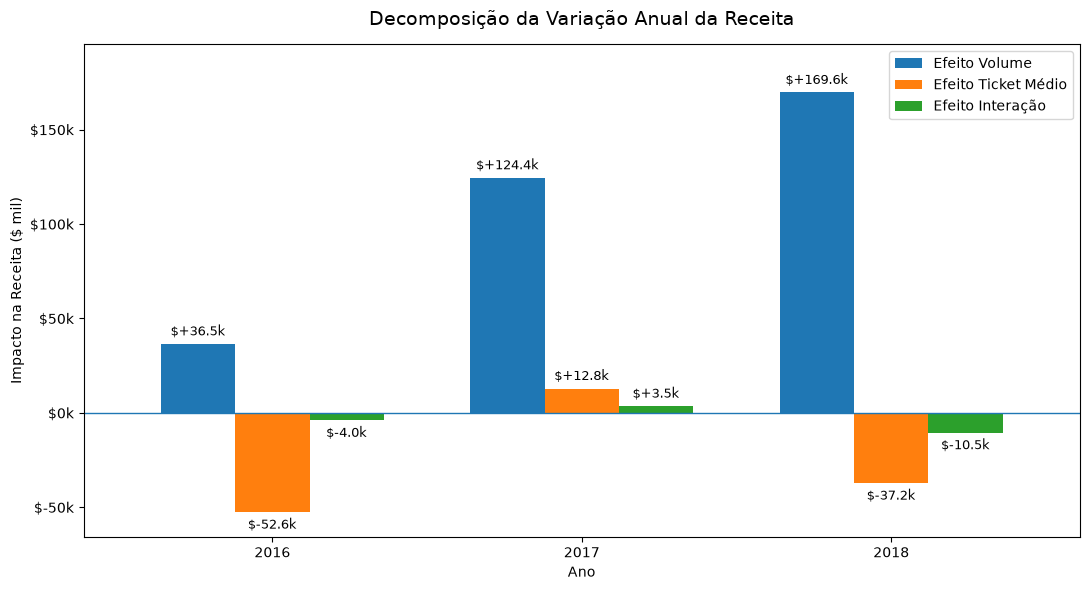

In [ ]:
decomposition_plot = decomposition.set_index("Year")[
    ["Volume_Effect", "AOV_Effect", "Interaction_Effect"]
]

ax = decomposition_plot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.72
)

ax.axhline(
    0,
    linewidth=1,
    label="_nolegend_"
)

ax.set_title(
    "Decomposição da Variação Anual da Receita",
    fontsize=14,
    pad=14
)

ax.set_xlabel("Ano")
ax.set_ylabel("Impacto na Receita ($ mil)")

ax.legend(
    [
        "Efeito Volume",
        "Efeito Ticket Médio",
        "Efeito Interação"
    ],
    frameon=True
)

# Formata o eixo Y em milhares
ax.yaxis.set_major_formatter(
    lambda value, position: f"${value / 1000:,.0f}k"
)

# Adiciona margem para as etiquetas
y_min = decomposition_plot.min().min()
y_max = decomposition_plot.max().max()

ax.set_ylim(
    y_min * 1.25,
    y_max * 1.15
)

# Etiquetas de dados
for container in ax.containers:
    labels = [
        f"${value / 1000:+,.1f}k"
        for value in container.datavalues
    ]

    ax.bar_label(
        container,
        labels=labels,
        padding=4,
        fontsize=9
    )

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
 

#### Interpretação

A decomposição evidencia que o **volume de pedidos foi o principal componente associado às variações da receita** ao longo do período.

Em 2016, o aumento do volume contribuiu positivamente com aproximadamente $36,46 mil, mas foi insuficiente para compensar o efeito negativo da redução do ticket médio (-$52,60 mil) e da interação entre os componentes (-$4,00 mil). Como resultado, a receita recuou aproximadamente $20,14 mil.

Em 2017, volume e ticket médio avançaram na mesma direção. O efeito volume adicionou aproximadamente $124,44 mil e o ticket médio mais $12,84 mil, contribuindo para um crescimento total de $140,76 mil na receita.

Em 2018, o efeito volume atingiu $169,63 mil, o maior do período. Apesar do impacto negativo do ticket médio (-$37,24 mil) e da interação (-$10,53 mil), a expansão do número de pedidos foi suficiente para sustentar um crescimento líquido de aproximadamente $121,86 mil.

Assim, a análise mostra que o crescimento comercial dos anos mais recentes foi sustentado principalmente pela **expansão do número de pedidos**, enquanto o ticket médio atuou como fator de amplificação em 2017 e de contenção em 2016 e 2018.

## 4. Performance por Dimensões de Negócio

A análise anterior demonstrou que a evolução da receita foi fortemente influenciada pelo crescimento do número de pedidos. Nesta seção, o objetivo é identificar **onde esse crescimento ocorreu dentro do negócio**.

Em vez de repetir a participação total de categorias, segmentos e regiões já explorada anteriormente, a análise concentra-se na evolução anual da receita e na contribuição de cada dimensão para suas variações.

### 4.1 — Performance por Categoria

A análise por categoria busca identificar quais áreas do portfólio contribuíram para o crescimento ou retração da receita em cada período.

In [ ]:
category_annual = (
    df.assign(Year=df["Order Date"].dt.year)
      .groupby(["Year", "Category"], as_index=False)
      .agg(Revenue=("Sales", "sum"))
)

category_annual

,Year,Category,Revenue
0,2015,Furniture,156196.5091
1,2015,Office Supplies,149512.8200
2,2015,Technology,173865.5070
3,2016,Furniture,164053.8674
4,2016,Office Supplies,133124.4070
5,2016,Technology,162257.7310
6,2017,Furniture,195813.0400
7,2017,Office Supplies,182417.5660
8,2017,Technology,221961.9440
9,2018,Furniture,212313.7872


In [ ]:
category_annual["Revenue_Change"] = (
    category_annual
    .groupby("Category")["Revenue"]
    .diff()
)

category_annual["Revenue_YoY"] = (
    category_annual
    .groupby("Category")["Revenue"]
    .pct_change()
)

In [ ]:
category_annual.style.format({
    "Year": "{:.0f}",
    "Revenue": "${:,.2f}",
    "Revenue_Change": "${:+,.2f}",
    "Revenue_YoY": "{:+.2%}"
}, na_rep="—")

,Year,Category,Revenue,Revenue_Change,Revenue_YoY
0,2015,Furniture,"$156,196.51",—,—
1,2015,Office Supplies,"$149,512.82",—,—
2,2015,Technology,"$173,865.51",—,—
3,2016,Furniture,"$164,053.87","$+7,857.36",+5.03%
4,2016,Office Supplies,"$133,124.41","$-16,388.41",-10.96%
5,2016,Technology,"$162,257.73","$-11,607.78",-6.68%
6,2017,Furniture,"$195,813.04","$+31,759.17",+19.36%
7,2017,Office Supplies,"$182,417.57","$+49,293.16",+37.03%
8,2017,Technology,"$221,961.94","$+59,704.21",+36.80%
9,2018,Furniture,"$212,313.79","$+16,500.75",+8.43%


In [ ]:
category_reconciliation = (
    category_annual
    .dropna(subset=["Revenue_Change"])
    .groupby("Year", as_index=False)
    .agg(
        Category_Revenue_Change=("Revenue_Change", "sum")
    )
)

category_reconciliation = category_reconciliation.merge(
    decomposition[["Year", "Revenue_Change"]],
    on="Year",
    how="left"
)

category_reconciliation["Difference"] = (
    category_reconciliation["Category_Revenue_Change"]
    - category_reconciliation["Revenue_Change"]
)

category_reconciliation.style.format({
    "Year": "{:.0f}",
    "Category_Revenue_Change": "${:+,.2f}",
    "Revenue_Change": "${:+,.2f}",
    "Difference": "${:,.6f}"
})

,Year,Category_Revenue_Change,Revenue_Change,Difference
0,2016,"$-20,138.83","$-20,138.83",$-0.000000
1,2017,"$+140,756.54","$+140,756.54",$-0.000000
2,2018,"$+121,859.47","$+121,859.47",$0.000000


In [ ]:
category_contribution = (
    category_annual
    .dropna(subset=["Revenue_Change"])
    [["Year", "Category", "Revenue_Change"]]
    .copy()
)

category_contribution_pivot = (
    category_contribution
    .pivot(
        index="Year",
        columns="Category",
        values="Revenue_Change"
    )
    .reset_index()
)

category_contribution_pivot.style.format({
    "Year": "{:.0f}",
    "Furniture": "${:+,.2f}",
    "Office Supplies": "${:+,.2f}",
    "Technology": "${:+,.2f}"
})

Category,Year,Furniture,Office Supplies,Technology
0,2016,"$+7,857.36","$-16,388.41","$-11,607.78"
1,2017,"$+31,759.17","$+49,293.16","$+59,704.21"
2,2018,"$+16,500.75","$+57,949.98","$+47,408.75"


#### Interpretação

A contribuição das categorias para a variação da receita não foi uniforme ao longo do período.

Em 2016, **Furniture** apresentou contribuição positiva de aproximadamente $7,86 mil, mas esse avanço foi insuficiente para compensar as retrações de **Office Supplies** (-$16,39 mil) e **Technology** (-$11,61 mil). O efeito combinado resultou na queda de $20,14 mil da receita total.

Em 2017, as três categorias passaram a contribuir positivamente para o crescimento. **Technology** apresentou o maior incremento (+$59,70 mil), seguida por **Office Supplies** (+$49,29 mil) e **Furniture** (+$31,76 mil).

Em 2018, o crescimento permaneceu distribuído entre as três categorias, mas sua composição mudou. **Office Supplies** passou a apresentar a maior contribuição (+$57,95 mil), seguida por **Technology** (+$47,41 mil) e **Furniture** (+$16,50 mil).

Os resultados mostram que o crescimento da receita não esteve concentrado permanentemente em uma única categoria. Embora Technology apresente a maior receita acumulada no período, os principais impulsionadores da variação anual mudaram ao longo do tempo.

### 4.2 — Performance por Segmento

A análise por segmento avalia como cada perfil de cliente contribuiu para as variações anuais da receita, permitindo identificar se o crescimento comercial ocorreu de forma distribuída ou esteve concentrado em determinados segmentos.

In [ ]:
segment_annual = (
    df.assign(Year=df["Order Date"].dt.year)
      .groupby(["Year", "Segment"], as_index=False)
      .agg(Revenue=("Sales", "sum"))
)

segment_annual["Revenue_Change"] = (
    segment_annual
    .groupby("Segment")["Revenue"]
    .diff()
)

segment_annual["Revenue_YoY"] = (
    segment_annual
    .groupby("Segment")["Revenue"]
    .pct_change()
)

segment_annual.style.format({
    "Year": "{:.0f}",
    "Revenue": "${:,.2f}",
    "Revenue_Change": "${:+,.2f}",
    "Revenue_YoY": "{:+.2%}"
}, na_rep="—")

,Year,Segment,Revenue,Revenue_Change,Revenue_YoY
0,2015,Consumer,"$262,956.80",—,—
1,2015,Corporate,"$127,797.50",—,—
2,2015,Home Office,"$88,820.54",—,—
3,2016,Consumer,"$265,356.29","$+2,399.49",+0.91%
4,2016,Corporate,"$119,675.60","$-8,121.90",-6.36%
5,2016,Home Office,"$74,404.11","$-14,416.43",-16.23%
6,2017,Consumer,"$291,142.97","$+25,786.67",+9.72%
7,2017,Corporate,"$204,977.32","$+85,301.72",+71.28%
8,2017,Home Office,"$104,072.27","$+29,668.15",+39.87%
9,2018,Consumer,"$328,604.47","$+37,461.51",+12.87%


In [ ]:
segment_contribution = (
    segment_annual
    .dropna(subset=["Revenue_Change"])
    [["Year", "Segment", "Revenue_Change"]]
    .copy()
)

segment_contribution_pivot = (
    segment_contribution
    .pivot(
        index="Year",
        columns="Segment",
        values="Revenue_Change"
    )
    .reset_index()
)

segment_contribution_pivot.style.format({
    "Year": "{:.0f}",
    "Consumer": "${:+,.2f}",
    "Corporate": "${:+,.2f}",
    "Home Office": "${:+,.2f}"
})

Segment,Year,Consumer,Corporate,Home Office
0,2016,"$+2,399.49","$-8,121.90","$-14,416.43"
1,2017,"$+25,786.67","$+85,301.72","$+29,668.15"
2,2018,"$+37,461.51","$+31,066.34","$+53,331.62"


#### Interpretação

A contribuição dos segmentos para a variação da receita mudou de forma significativa entre os anos.

Em 2016, **Consumer** apresentou crescimento moderado (+$2,40 mil), enquanto **Corporate** (-$8,12 mil) e principalmente **Home Office** (-$14,42 mil) contribuíram negativamente. O efeito combinado explica a retração da receita observada no período.

Em 2017, os três segmentos passaram a contribuir positivamente, com destaque para **Corporate**, responsável pelo maior incremento (+$85,30 mil). Consumer adicionou aproximadamente $25,79 mil e Home Office $29,67 mil.

Em 2018, o crescimento permaneceu distribuído entre todos os segmentos, mas a liderança da contribuição mudou novamente. **Home Office** apresentou o maior incremento (+$53,33 mil), seguido por Consumer (+$37,46 mil) e Corporate (+$31,07 mil).

Os resultados mostram que, embora **Consumer concentre a maior receita acumulada**, ele não foi o principal impulsionador do crescimento em todos os períodos. A origem incremental da receita mudou de **Corporate em 2017 para Home Office em 2018**, evidenciando que participação total e contribuição para o crescimento representam perspectivas distintas do desempenho comercial.

### 4.3 — Performance por Região

A análise regional avalia como cada mercado geográfico contribuiu para as variações anuais da receita, permitindo identificar mudanças na origem regional do crescimento comercial.

In [ ]:
region_annual = (
    df.assign(Year=df["Order Date"].dt.year)
      .groupby(["Year", "Region"], as_index=False)
      .agg(Revenue=("Sales", "sum"))
)

region_annual["Revenue_Change"] = (
    region_annual
    .groupby("Region")["Revenue"]
    .diff()
)

region_annual["Revenue_YoY"] = (
    region_annual
    .groupby("Region")["Revenue"]
    .pct_change()
)

region_annual.style.format({
    "Year": "{:.0f}",
    "Revenue": "${:,.2f}",
    "Revenue_Change": "${:+,.2f}",
    "Revenue_YoY": "{:+.2%}"
}, na_rep="—")

,Year,Region,Revenue,Revenue_Change,Revenue_YoY
0,2015,Central,"$102,920.52",—,—
1,2015,East,"$127,371.45",—,—
2,2015,South,"$103,374.91",—,—
3,2015,West,"$145,907.96",—,—
4,2016,Central,"$102,425.17",$-495.35,-0.48%
5,2016,East,"$153,225.18","$+25,853.74",+20.30%
6,2016,South,"$70,076.08","$-33,298.82",-32.21%
7,2016,West,"$133,709.57","$-12,198.40",-8.36%
8,2017,Central,"$145,673.88","$+43,248.71",+42.22%
9,2017,East,"$178,511.54","$+25,286.36",+16.50%


#### Interpretação

A evolução regional mostra que o desempenho da receita não ocorreu de forma uniforme entre os mercados.

Em 2016, **East** foi a única região com crescimento relevante, avançando 20,30% (+$25,85 mil). Esse desempenho, porém, não foi suficiente para compensar as retrações de **South** (-32,21%), **West** (-8,36%) e a estabilidade de **Central** (-0,48%), contribuindo para a queda da receita total naquele ano.

Em 2017, o cenário se tornou amplamente positivo. Todas as regiões apresentaram crescimento, com destaque percentual para **Central** (+42,22%) e, em termos absolutos, para **West** (+$48,76 mil). South e East também avançaram, indicando que a expansão da receita ocorreu de forma distribuída regionalmente.

Em 2018, **West** manteve forte crescimento (+35,98%) e adicionou aproximadamente $65,66 mil em receita, o maior incremento regional do ano. **South** (+30,61%) e **East** (+17,71%) também avançaram, enquanto **Central** apresentou leve retração de -2,78%.

A análise evidencia, portanto, uma mudança na dinâmica regional ao longo do período: 2016 foi marcado por desempenhos divergentes entre as regiões, enquanto 2017 apresentou expansão generalizada. Em 2018, o crescimento permaneceu positivo na maior parte dos mercados, com **West assumindo papel particularmente relevante na expansão da receita**.

In [ ]:
region_reconciliation = (
    region_annual
    .dropna(subset=["Revenue_Change"])
    .groupby("Year", as_index=False)
    .agg(
        Region_Revenue_Change=("Revenue_Change", "sum")
    )
)

region_reconciliation = region_reconciliation.merge(
    decomposition[["Year", "Revenue_Change"]],
    on="Year",
    how="left"
)

region_reconciliation["Difference"] = (
    region_reconciliation["Region_Revenue_Change"]
    - region_reconciliation["Revenue_Change"]
)

region_reconciliation.style.format({
    "Year": "{:.0f}",
    "Region_Revenue_Change": "${:+,.2f}",
    "Revenue_Change": "${:+,.2f}",
    "Difference": "${:,.6f}"
})

,Year,Region_Revenue_Change,Revenue_Change,Difference
0,2016,"$-20,138.83","$-20,138.83",$0.000000
1,2017,"$+140,756.54","$+140,756.54",$0.000000
2,2018,"$+121,859.47","$+121,859.47",$0.000000


In [ ]:
region_contribution = (
    region_annual
    .dropna(subset=["Revenue_Change"])
    [["Year", "Region", "Revenue_Change"]]
    .copy()
)

region_contribution_pivot = (
    region_contribution
    .pivot(
        index="Year",
        columns="Region",
        values="Revenue_Change"
    )
    .reset_index()
)

region_contribution_pivot.style.format({
    "Year": "{:.0f}",
    "Central": "${:+,.2f}",
    "East": "${:+,.2f}",
    "South": "${:+,.2f}",
    "West": "${:+,.2f}"
})

Region,Year,Central,East,South,West
0,2016,$-495.35,"$+25,853.74","$-33,298.82","$-12,198.40"
1,2017,"$+43,248.71","$+25,286.36","$+23,459.82","$+48,761.66"
2,2018,"$-4,046.54","$+31,617.65","$+28,628.66","$+65,659.70"


#### Contribuição Regional para a Variação da Receita

A decomposição em valores absolutos confirma que a origem regional da variação da receita mudou ao longo do período.

Em 2016, o crescimento de East (+$25,85 mil) foi insuficiente para compensar principalmente a retração de South (-$33,30 mil) e West (-$12,20 mil). Em 2017, todas as regiões contribuíram positivamente, com West apresentando o maior incremento (+$48,76 mil). Em 2018, West ampliou essa contribuição para +$65,66 mil, consolidando-se como o principal componente regional do crescimento naquele ano.

## 5. Síntese da Análise de Vendas

### 5.1 — Principais Achados

A análise evidencia que a evolução da receita foi determinada por diferentes combinações de volume, ticket médio e contribuição das dimensões de negócio ao longo do período.

- **O crescimento recente foi sustentado principalmente pelo aumento do volume de pedidos.** Em 2018, o efeito volume adicionou aproximadamente $169,63 mil à receita, compensando os efeitos negativos do ticket médio (-$37,24 mil) e da interação (-$10,53 mil). O resultado foi um crescimento líquido de aproximadamente $121,86 mil.

- **Volume e ticket médio não evoluíram sempre na mesma direção.** Em 2016, o crescimento dos pedidos não foi suficiente para evitar a retração da receita diante da redução do ticket médio. Em 2017, ambos contribuíram positivamente, produzindo o maior crescimento anual do período (+$140,76 mil).

- **Os drivers de crescimento por categoria mudaram entre os anos.** Technology apresentou a maior contribuição em 2017 (+$59,70 mil), enquanto Office Supplies assumiu a maior contribuição em 2018 (+$57,95 mil). Isso demonstra que liderança em receita acumulada e contribuição incremental representam perspectivas distintas.

- **A origem do crescimento também mudou entre os segmentos de clientes.** Corporate apresentou o maior incremento em 2017 (+$85,30 mil), enquanto Home Office liderou a contribuição em 2018 (+$53,33 mil), apesar de Consumer permanecer como o maior segmento em receita acumulada.

- **Regionalmente, West ganhou relevância como motor de expansão.** Após contribuir negativamente em 2016, a região apresentou o maior incremento absoluto em 2017 (+$48,76 mil) e ampliou sua contribuição em 2018 (+$65,66 mil).

Em conjunto, os resultados mostram que o desempenho comercial não pode ser explicado apenas pela evolução da receita total. A análise dos seus componentes revela mudanças relevantes na origem do crescimento ao longo do tempo, tanto na dinâmica entre volume e ticket médio quanto na contribuição de categorias, segmentos e regiões.

### 5.2 — Implicações para as Próximas Análises

A análise de vendas permitiu identificar os principais mecanismos e origens da variação da receita, mas algumas questões permanecem fora do seu escopo.

A mudança da contribuição entre Consumer, Corporate e Home Office indica a necessidade de avaliar o comportamento dos clientes em maior profundidade, considerando aspectos como frequência de compra, valor gerado e concentração da receita por cliente.

Da mesma forma, as diferenças observadas entre categorias não permitem identificar quais produtos específicos sustentam esses resultados. Uma análise em nível de produto poderá avaliar concentração da receita, itens de maior valor e sua participação nas transações de maior impacto econômico.

A dimensão logística também permanece independente da análise comercial, permitindo investigar posteriormente como modos e tempos de envio se comportam entre pedidos, regiões e demais características da operação.

Por fim, os padrões temporais identificados anteriormente ainda exigem tratamento específico de séries temporais para avaliar formalmente tendência, sazonalidade e capacidade de previsão.